In [1]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import TwoSlopeNorm

from beta_evidence_field import (OccupancyField,
                                 OccupancyObservation)

from tools.plotting import configure_plots


configure_plots()

# Sampling-Density Normalisation

Repeated measurements from similar sensor states should not cause accumulated evidence to increase purely as a consequence of sampling density.

Each observation is therefore weighted by the inverse local density of observations in sensor-state space,

$$
w_i =
\left[
\sum_j
\exp\left(
-\frac{1}{2}d_s^2(s_i,s_j)
\right)
\right]^{-1}.
$$

This notebook examines the behaviour of this normalisation for repeated observations and increasingly dense sampling of the same continuous observation trajectory.

## Repeated Observations

For $N$ identical observations, all pairwise state similarities are one. The local sampling density is therefore

$$
\rho_i = N,
$$

giving each observation weight

$$
w_i = \frac{1}{N}.
$$

The total effective weight consequently remains equal to one, regardless of the number of repeated observations.

In [2]:
sample_counts = np.linspace(5, 500, 50, dtype = int)

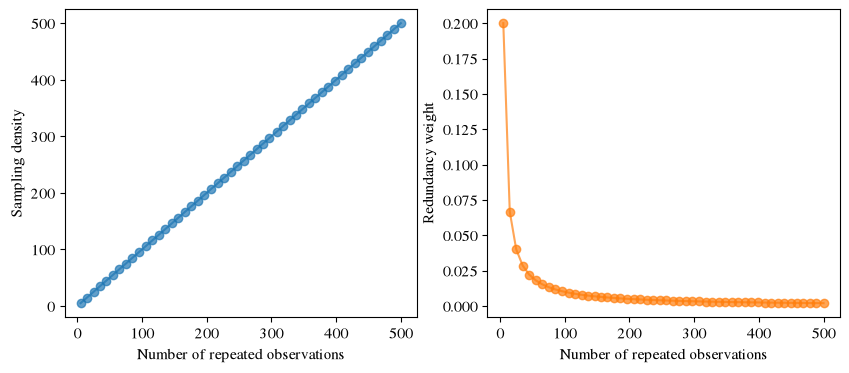

In [3]:
def repeated_observations(n):

    return [OccupancyObservation(origin    = np.array([0.0, 0.0]),
                                 direction = np.array([1.0, 0.0]),
                                 range     = 1.0,
                                 returned  = True,
                                 time      = 0.0)
            for _ in range(n)]


densities = []
weights   = []

for n in sample_counts:

    field = OccupancyField.from_yaml("../config/example_2d_config.yaml")
    field.add(repeated_observations(n))

    states = np.asarray([observation.state
                         for observation in field.observations])

    distance = field.state_kernel.distance(points = states[:, None, :],
                                           centre = states[None, :, :])

    density = np.sum(np.exp(-0.5 * distance), axis = 1)

    densities.append(density[0])
    weights.append(1.0/density[0])


densities = np.asarray(densities)
weights   = np.asarray(weights)


fig, axes = plt.subplots(1,
                         2,
                         figsize = (10, 4))

axes[0].plot(sample_counts,
             densities,
             "o-",
             color = "tab:blue",
             alpha = 0.7)

axes[1].plot(sample_counts,
             weights,
             "o-",
             color = "tab:orange",
             alpha = 0.7)

axes[0].set_xlabel("Number of repeated observations")
axes[0].set_ylabel("Sampling density")

axes[1].set_xlabel("Number of repeated observations")
axes[1].set_ylabel("Redundancy weight")

plt.show()


### Sampling-Density Convergence

To test the effect of sampling density, the same underlying observation set is represented using an increasing number of samples.

The total weight assigned to each discretisation is

$$
W_N = \sum_{i=1}^{N} w_i.
$$

As the sampling becomes denser, additional observations are increasingly redundant and receive correspondingly smaller weights. The total weight should therefore converge to a finite value rather than continue increasing with the number of observations.

To show this convergence clearly, the total weight is expressed relative to a densely sampled reference,

$$
\bar W_N =
\frac{W_N}{W_{\mathrm{ref}}},
$$

such that

$$
\bar W_N \rightarrow 1.
$$

A value approaching one indicates that further increasing the sampling density no longer materially changes the total weight assigned to the observation set.

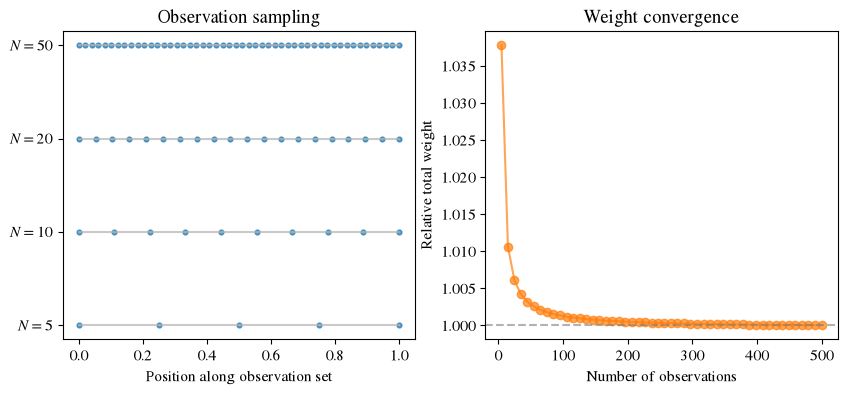

In [4]:
def observation_set(n):

    y = np.linspace(0.0, 1.0, n)

    return [OccupancyObservation(origin    = np.array([0.0, y_i]),
                                 direction = np.array([1.0, 0.0]),
                                 range     = 1.0,
                                 returned  = True,
                                 time      = 0.0)
            for y_i in y]


coverage = []

for n in sample_counts:

    field = OccupancyField.from_yaml("../config/example_2d_config.yaml")
    field.add(observation_set(n))

    weights = field._redundancy_weights(field.observations)

    coverage.append(np.sum(weights))


coverage          = np.asarray(coverage)
relative_coverage = coverage / coverage[-1]


fig, axes = plt.subplots(1,
                         2,
                         figsize = (10, 4))

# Observation sampling
display_counts = [5, 10, 20, 50]

for row, n in enumerate(display_counts):

    observations = observation_set(n)

    y = np.asarray([observation.origin[1]
                    for observation in observations])

    axes[0].plot([0.0, 1.0],
                 [row, row],
                 color     = "0.7",
                 linewidth = 1.5,
                 alpha     = 0.7)

    axes[0].scatter(y,
                    np.full_like(y, row),
                    color = "tab:blue",
                    s     = 12,
                    alpha = 0.7)

axes[0].set_yticks(range(len(display_counts)),
                   [f"$N = {n}$" for n in display_counts])

axes[0].set_xlabel("Position along observation set")
axes[0].set_title("Observation sampling")


# Coverage convergence
axes[1].plot(sample_counts,
             relative_coverage,
             "o-",
             color = "tab:orange",
             alpha = 0.7)

axes[1].axhline(1.0,
                color     = "0.5",
                linestyle = "--",
                alpha     = 0.6)

axes[1].set_xlabel("Number of observations")
axes[1].set_ylabel("Relative total weight")
axes[1].set_title("Weight convergence")

plt.show()

## Field Convergence

Convergence of the observation weights should result in convergence of the Beta Evidence Field itself.

As the same underlying observation set is sampled increasingly densely, the accumulated occupied and free-space evidence should approach stable continuous fields,

$$
\alpha_N(x) \rightarrow \alpha_\infty(x),
\qquad
\beta_N(x) \rightarrow \beta_\infty(x).
$$

Consequently, the resulting occupancy probability,

$$
P_N(x)
=
\frac{\alpha_N(x)}
{\alpha_N(x)+\beta_N(x)},
$$

should also converge,

$$
P_N(x)\rightarrow P_\infty(x).
$$

Increasing the sampling density therefore refines the discrete representation of the observations without continually increasing the evidence or changing the resulting occupancy field.

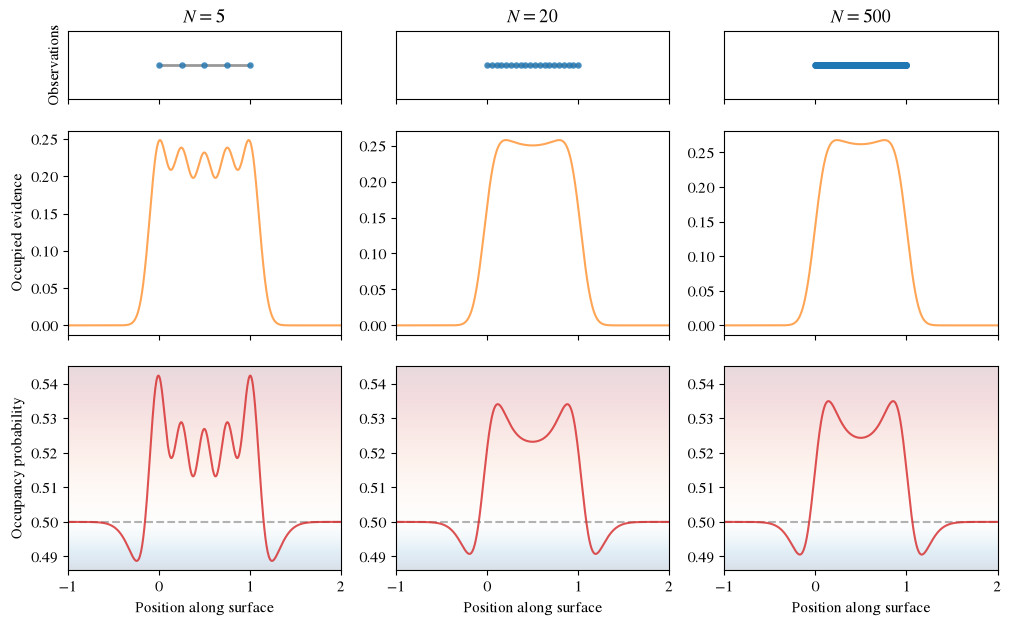

In [5]:

y      = np.linspace(-1, 2, 500)
points = np.column_stack((np.ones_like(y),
                          y))

sample_counts = [5, 20, 500]

evidences     = []
probabilities = []
positions     = []


for n in sample_counts:

    field = OccupancyField.from_yaml("../config/example_2d_config.yaml")
    field.add(observation_set(n))

    prior = field.prior.evaluate(points)[0]
    query = field.query(points)

    evidences.append(query.alpha - prior)
    probabilities.append(query.alpha/(query.alpha + query.beta))
    positions.append(np.asarray([observation.endpoint[1]
                                 for observation in field.observations]))


probability_min = min(np.min(probability)
                      for probability in probabilities)

probability_max = max(np.max(probability)
                      for probability in probabilities)

probability_pad = 0.05*(probability_max - probability_min)

probability_min -= probability_pad
probability_max += probability_pad

gradient = np.linspace(probability_min,
                       probability_max,
                       256)[:, None]

norm = TwoSlopeNorm(vmin    = probability_min,
                    vcenter = 0.5,
                    vmax    = probability_max)


fig, axes = plt.subplots(3,
                         len(sample_counts),
                         figsize = (12, 7),
                         sharex = True,
                         gridspec_kw = {"height_ratios": [1, 3, 3]})


for column, (n, evidence, probability, position) in enumerate(
        zip(sample_counts, evidences, probabilities, positions)):

    # Observations
    axes[0, column].plot([0.0, 1.0],
                         [0.0, 0.0],
                         color     = "0.6",
                         linewidth = 2.0)

    axes[0, column].scatter(position,
                            np.zeros_like(position),
                            color  = "tab:blue",
                            s      = 14,
                            alpha  = 0.7,
                            zorder = 2)

    axes[0, column].set_title(f"$N = {n}$")
    axes[0, column].set_yticks([])

    # Occupied evidence
    axes[1, column].plot(y,
                         evidence,
                         color = "tab:orange",
                         alpha = 0.7)

    # Occupancy probability background
    axes[2, column].imshow(gradient,
                           extent = [y.min(),
                                     y.max(),
                                     probability_min,
                                     probability_max],
                           origin = "lower",
                           aspect = "auto",
                           cmap   = "RdBu_r",
                           norm   = norm,
                           alpha  = 0.15,
                           zorder = 0)

    # Occupancy probability
    axes[2, column].plot(y,
                         probability,
                         color  = "tab:red",
                         alpha  = 0.8,
                         zorder = 2)

    axes[2, column].axhline(0.5,
                            color     = "0.5",
                            linestyle = "--",
                            alpha     = 0.6,
                            zorder    = 1)

    axes[2, column].set_ylim(probability_min,
                             probability_max)

    axes[2, column].set_xlabel("Position along surface")


axes[0, 0].set_ylabel("Observations")
axes[1, 0].set_ylabel("Occupied evidence")
axes[2, 0].set_ylabel("Occupancy probability")

plt.show()

## Temporal Separation

Sampling-density normalisation should suppress repeated observations only while the observations remain similar in state space. Repeated measurements separated in time can therefore provide additional evidence.

For otherwise identical observations separated by $\Delta t$, their temporal similarity is

$$
k_t(\Delta t)
=
\exp\left(
-\frac{1}{2}
\frac{\Delta t^2}{\sigma_t^2}
\right),
$$

where $\sigma_t^2$ is the temporal component of the state covariance.

At zero temporal separation, identical observations are fully redundant and share a total weight of one. As the temporal separation increases, their similarity decreases and both observations increasingly contribute independently. The total weight therefore approaches two,

$$
W(\Delta t)
=
\sum_i w_i
\rightarrow 2.
$$

This allows repeated observations to increase the accumulated evidence when they represent sufficiently separated measurements, while preventing closely correlated samples from being counted as independent evidence.

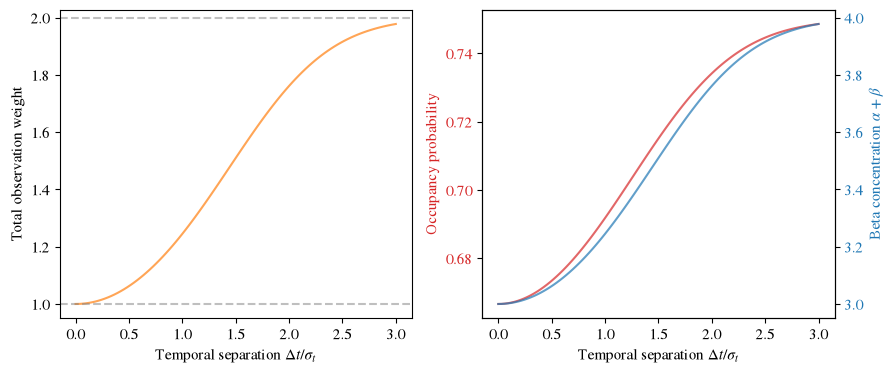

In [7]:
field = OccupancyField.from_yaml("../config/example_2d_config.yaml")

temporal_sigma = np.sqrt(field.temporal_variance)

separations = np.linspace(0.0,
                          field.temporal_support_sigma*temporal_sigma,
                          100)

total_weights  = []
probabilities  = []
concentrations = []


for separation in separations:

    observations = [
        OccupancyObservation(origin    = np.array([0.0, 0.0]),
                             direction = np.array([1.0, 0.0]),
                             range     = 1.0,
                             returned  = True,
                             time      = 0.0),

        OccupancyObservation(origin    = np.array([0.0, 0.0]),
                             direction = np.array([1.0, 0.0]),
                             range     = 1.0,
                             returned  = True,
                             time      = separation),
    ]

    # Redundancy of the complete pair
    weights = field._redundancy_weights(observations)

    total_weights.append(np.sum(weights))

    # Actual field update
    field_i = OccupancyField.from_yaml("../config/example_2d_config.yaml")

    if np.isclose(separation, 0.0):
        field_i.add(observations)
    else:
        field_i.add([observations[0]])
        field_i.add([observations[1]])

    query = field_i.query(observations[0].endpoint)

    probabilities.append(query.alpha/(query.alpha + query.beta))
    concentrations.append(query.alpha + query.beta)


total_weights  = np.asarray(total_weights)
probabilities  = np.asarray(probabilities)
concentrations = np.asarray(concentrations)


fig, axes = plt.subplots(1,
                         2,
                         figsize = (10, 4))


# Temporal redundancy
axes[0].plot(separations/temporal_sigma,
             total_weights,
             color = "tab:orange",
             alpha = 0.7)

axes[0].axhline(1.0,
                color     = "0.5",
                linestyle = "--",
                alpha     = 0.5)

axes[0].axhline(2.0,
                color     = "0.5",
                linestyle = "--",
                alpha     = 0.5)

axes[0].set_xlabel(r"Temporal separation $\Delta t/\sigma_t$")
axes[0].set_ylabel("Total observation weight")


# Resulting BEF
probability_axis   = axes[1]
concentration_axis = probability_axis.twinx()

probability_axis.plot(separations/temporal_sigma,
                      probabilities,
                      color = "tab:red",
                      alpha = 0.7)

concentration_axis.plot(separations/temporal_sigma,
                        concentrations,
                        color = "tab:blue",
                        alpha = 0.7)

probability_axis.set_xlabel(r"Temporal separation $\Delta t/\sigma_t$")
probability_axis.set_ylabel("Occupancy probability",
                            color = "tab:red")

concentration_axis.set_ylabel(r"Beta concentration $\alpha + \beta$",
                              color = "tab:blue")

probability_axis.tick_params(axis = "y",
                             labelcolor = "tab:red")

concentration_axis.tick_params(axis = "y",
                               labelcolor = "tab:blue")

plt.show()

## Summary

Sampling-density normalisation prevents accumulated evidence from depending directly on the number of observations used to represent the same underlying measurements.

Identical observations share their contribution, with each receiving a weight of \(1/N\). For increasingly dense sampling of a continuous observation set, the total density-normalised weight converges rather than increasing with the number of samples. This convergence carries through to the Beta Evidence Field, producing stable occupied evidence and occupancy probability as the sampling density increases.

The normalisation does not prevent additional measurements from increasing evidence. Observations become progressively less redundant as they separate in observation state space. In particular, repeated measurements separated by several temporal correlation scales approach independent contributions.

The resulting field therefore accumulates evidence according to the diversity of the observed sensor states rather than the raw number of measurements.